# Inferring sparse feeding controls from glucose

We compare NumPyro NUTS, joint Adaptive Metropolis, and the Metropolis-adjusted Langevin algorithm (MALA) on the same fixed-key EnKF posterior. The unknowns are insulin sensitivity $S$, secretion $B$, and 24 positive feeding doses. Eight glucose measurements constrain the broad timing and amount of feeding. Nearby bins can yield similar glucose trajectories.

For a dose $a_j$ in the five-minute bin starting at $5j$, the input rate $u(t)$ is $a_j/5$ in that bin and zero from minute 120 onward. The fasting initial state is $(G,J,Q)_0=(5,0,0)$.

$$
\begin{aligned}
dG &= [0.035Q-0.015(G-5)-SJG]dt+0.025\,dW_G,\\
dJ &= [B(G-5)-0.08J]dt+0.12\,dW_J,\\
dQ &= [u(t)-0.035Q]dt,\\
y_i &\sim \mathcal{N}(G(t_i),0.25^2),\\
\log S &\sim\mathcal{N}(\log 0.001,0.7^2),\qquad
\log B\sim\mathcal{N}(\log 0.8,0.7^2).
\end{aligned}
$$

Each dose has an independent positive regularized horseshoe prior with fixed global scale $\tau=0.20$ and slab scale $c=6$. Conditional on $\lambda_j\sim\operatorname{HalfCauchy}(1)$, the dose is half-normal with scale $c\tau\lambda_j/\sqrt{c^2+\tau^2\lambda_j^2}$. We integrate out each local scale, leaving 26 continuous coordinates. The posterior probability $P(a_j>1\mid y)$ refers to a dose threshold of one gut-load unit. [Regularized horseshoe formulation](https://arxiv.org/abs/1707.01694)

In [1]:
import numpyro

numpyro.set_host_device_count(4)

import json
import time
from importlib.metadata import version
from pathlib import Path

import jax

jax.config.update("jax_enable_x64", True)

import arviz as az
import blackjax
import jax.numpy as jnp
import jax.random as jr
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
import pandas as pd
from IPython.display import display
from jax.flatten_util import ravel_pytree
from numpyro.infer import MCMC, NUTS, Predictive, init_to_median
from numpyro.infer.util import initialize_model, log_density
from scipy.special import roots_legendre

import dynestyx as dsx
from dynestyx.inference.configs.discretizer import EulerMaruyamaConfig
from dynestyx.inference.configs.filter import EnKFConfig
from dynestyx.inference.configs.mcmc import AdaptiveMetropolisConfig, MALAConfig
from dynestyx.inference.mcmc import MCMCInference

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "dynestyx").is_dir())
OUT = ROOT / "examples/ogtt_sde/results/feeding_benchmark_long"
OUT.mkdir(parents=True, exist_ok=True)

N_BINS, BIN_MINUTES = 24, 5.0
BIN_EDGES = BIN_MINUTES * jnp.arange(N_BINS + 1, dtype=jnp.float64)
TAU, SLAB = 0.20, 6.0
DOSE_THRESHOLD = 1.0
TRUE_S, TRUE_B = 0.001, 0.8
TRUE_DOSE = jnp.zeros(N_BINS).at[jnp.array([1, 10, 20])].set(jnp.array([7.0, 6.0, 5.0]))
OBS_TIMES = jnp.arange(0.0, 181.0, 5.0)
OBS_SD = 0.25
ENSEMBLE, FILTER_DT, SIM_DT = 30, 0.5, 0.025
SIM_SEED, FILTER_SEED = 12, 0
NUTS_SEED, MH_SEED, MALA_SEED = 42, 43, 44
NUM_CHAINS = 4

devices = jax.local_devices()
print("JAX devices:", devices)
if len(devices) < NUM_CHAINS:
    raise RuntimeError(
        f"Expected at least {NUM_CHAINS} JAX devices, found {len(devices)}. "
        "Restart the kernel and run this cell first."
    )

NUTS_WARMUP, NUTS_DRAWS = 500, 500
MH_WARMUP, MH_DRAWS = 1000, 23000
MALA_WARMUP, MALA_DRAWS = 1000, 21000
MALA_STEP_SIZE = 0.003
NUTS_TARGET, MH_TARGET, MH_INITIAL_SCALE = 0.9, 0.234, 0.1
INIT = init_to_median(num_samples=15)
SITES = ("sensitivity", "secretion", "feeding_dose")

VERSIONS = {
    name: version(name)
    for name in ("arviz", "blackjax", "cuthbert", "dynestyx", "jax", "numpyro")
}


JAX devices: [CpuDevice(id=0), CpuDevice(id=1), CpuDevice(id=2), CpuDevice(id=3)]


## Marginal dose prior and controlled dynamics

On the log-local-scale axis, $r=\log\lambda$ has density $1/(\pi\cosh r)$. Gauss–Legendre quadrature on $[-28,28]$ approximates the integral as a weighted half-normal mixture. NumPyro sums over the mixture components in its log density. The samplers work in unconstrained log-dose coordinates.

The control arrays follow the simulation or filter grid. At a bin boundary, the new rate applies to the interval that starts there.

In [2]:
def marginal_dose_prior(num_nodes):
    nodes, weights = roots_legendre(num_nodes)
    r = 28.0 * jnp.asarray(nodes)
    logits = jnp.log(weights) - jnp.logaddexp(r, -r)
    h = TAU * jnp.exp(r)
    scales = SLAB * (h / jnp.hypot(SLAB, h))
    return dist.MixtureSameFamily(dist.Categorical(logits=logits), dist.HalfNormal(scales))


dose_prior = marginal_dose_prior(320)
reference_prior = marginal_dose_prior(768)


def check_prior(lower, upper):
    log_doses = jnp.linspace(np.log(lower), np.log(upper), 401)

    def evaluate(prior):
        def log_density_on_log_scale(log_dose):
            return prior.log_prob(jnp.exp(log_dose)) + log_dose

        return jax.vmap(jax.value_and_grad(log_density_on_log_scale))(log_doses)

    values, slopes = evaluate(dose_prior)
    ref_values, ref_slopes = evaluate(reference_prior)
    np.testing.assert_allclose(values, ref_values, atol=1e-6, rtol=0)
    np.testing.assert_allclose(slopes, ref_slopes, atol=1e-5, rtol=0)
    return {
        "dose_range": [float(lower), float(upper)],
        "max_log_density_error": float(jnp.max(jnp.abs(values - ref_values))),
        "max_log_dose_gradient_error": float(jnp.max(jnp.abs(slopes - ref_slopes))),
    }


prior_check = check_prior(1e-8, 40.0)
print(prior_check)


def control_rates(times, dose):
    bins = jnp.searchsorted(BIN_EDGES[1:], times, side="right")
    rates = jnp.concatenate([dose / BIN_MINUTES, jnp.zeros_like(dose[:1])])
    return rates[bins, None]


def controlled_path(s, b, dose, *, obs_times=None, obs_values=None, predict_times=None):
    def drift(x, u, t):
        g, j, q = x
        return jnp.array([
            0.035 * q - 0.015 * (g - 5.0) - s * j * g,
            b * (g - 5.0) - 0.08 * j,
            u[0] - 0.035 * q,
        ])

    dynamics = dsx.DynamicalModel(
        initial_condition=dist.Delta(jnp.array([5.0, 0.0, 0.0]), event_dim=1),
        state_evolution=dsx.ContinuousTimeStateEvolution(
            drift=drift,
            diffusion=dsx.FullDiffusion(jnp.array([[0.025, 0.0], [0.0, 0.12], [0.0, 0.0]])),
        ),
        observation_model=dsx.LinearGaussianObservation(
            H=jnp.array([[1.0, 0.0, 0.0]]), R=jnp.array([[OBS_SD**2]]),
        ),
        control_dim=1,
    )
    times = obs_times if predict_times is None else predict_times
    return dsx.sample(
        "ogtt", dynamics, obs_times=obs_times, obs_values=obs_values,
        predict_times=predict_times, ctrl_times=times, ctrl_values=control_rates(times, dose),
    )


def feeding_model(obs_times=None, obs_values=None, ctrl_times=None, ctrl_values=None):
    s = numpyro.sample("sensitivity", dist.LogNormal(jnp.log(TRUE_S), 0.7))
    b = numpyro.sample("secretion", dist.LogNormal(jnp.log(TRUE_B), 0.7))
    with numpyro.plate("feeding_bin", N_BINS):
        dose = numpyro.sample("feeding_dose", dose_prior)
    return controlled_path(s, b, dose, obs_times=obs_times, obs_values=obs_values)

{'dose_range': [1e-08, 40.0], 'max_log_density_error': 2.2448175762690425e-07, 'max_log_dose_gradient_error': 5.0906016768603735e-06}


## Simulate data and verify the common target

Simulate the SDE at a finer step than the filter. The dense trajectory is synthetic truth. Only the eight scheduled glucose values enter the likelihood. The remaining steps on the filter grid carry missing observations. Fixing the ensemble key gives both samplers the same deterministic approximation to the marginal likelihood.

In [3]:
sim_times = jnp.arange(721) * 0.25
fine_times = jnp.arange(361) * FILTER_DT

# Check the last bin, including the switch to zero at minute 120.
pulse = jnp.zeros(N_BINS).at[-1].set(7.0)
for times in (sim_times, fine_times):
    rates = control_rates(times, pulse)[:, 0]
    np.testing.assert_array_equal(rates > 0, (times >= 115) & (times < 120))
    np.testing.assert_allclose(jnp.sum(rates[:-1] * jnp.diff(times)), 7.0, rtol=0, atol=1e-12)


def simulate(predict_times):
    return controlled_path(TRUE_S, TRUE_B, TRUE_DOSE, predict_times=predict_times)


with dsx.SDESimulator(dsx.SDESimulatorConfig(dt0=SIM_DT)):
    simulated = Predictive(simulate, num_samples=1)(jr.PRNGKey(SIM_SEED), sim_times)
true_states = simulated["ogtt_states"][0, 0]
sim_indices = np.searchsorted(sim_times, OBS_TIMES)
obs_indices = np.searchsorted(fine_times, OBS_TIMES)
np.testing.assert_array_equal(sim_times[sim_indices], OBS_TIMES)
np.testing.assert_array_equal(fine_times[obs_indices], OBS_TIMES)
observations = simulated["ogtt_observations"][0, 0, sim_indices]
fine_y = jnp.full((fine_times.size, 1), jnp.nan).at[obs_indices].set(observations)

np.savez_compressed(
    OUT / "data.npz", times=sim_times, states=true_states, obs_times=OBS_TIMES,
    observations=observations, bin_edges=BIN_EDGES, true_doses=TRUE_DOSE,
)


def filter_context():
    return dsx.Filter(EnKFConfig(
        n_particles=ENSEMBLE, crn_seed=jr.PRNGKey(FILTER_SEED), warn=False,
        record_filtered_states_mean=False, record_filtered_states_cov=False,
        record_filtered_particles=False, include_predicted_observations=False,
        record_predicted_observations_mean=False, record_predicted_observations_cov=False,
        record_predicted_observations_ensemble=False,
    ))


def discretizer():
    return dsx.Discretizer(EulerMaruyamaConfig(covariance_jitter=1e-12))


model_kwargs = {"obs_times": fine_times, "obs_values": fine_y}
with filter_context(), discretizer():
    model_info = initialize_model(
        jr.PRNGKey(0), feeding_model, model_kwargs=model_kwargs,
        init_strategy=INIT, forward_mode_differentiation=True,
    )
    flat_init, unravel = ravel_pytree(model_info.param_info.z)
    assert set(model_info.param_info.z) == set(SITES)
    assert flat_init.size == N_BINS + 2
    params = model_info.postprocess_fn(model_info.param_info.z)
    log_targets = [
        log_density(numpyro.handlers.seed(feeding_model, key), (), model_kwargs, params)[0]
        for key in (0, 123)
    ]
    assert np.isfinite(log_targets).all()
    np.testing.assert_allclose(*log_targets, atol=1e-12, rtol=0)

    def potential(flat):
        return model_info.potential_fn(unravel(flat))

    probe_points = jnp.stack([flat_init, flat_init + 0.25 * jr.normal(jr.PRNGKey(1), flat_init.shape)])
    forward = jax.jit(jax.vmap(jax.jacfwd(potential)))(probe_points)
    assert np.isfinite(forward).all()
    use_forward_mode = False
    gradient_error = None
    try:
        reverse = jax.jit(jax.vmap(jax.grad(potential)))(probe_points)
        np.testing.assert_allclose(reverse, forward, atol=1e-7, rtol=1e-6)
        gradient_error = float(jnp.max(jnp.abs(forward - reverse)))
    except (ValueError, NotImplementedError, AssertionError) as error:
        use_forward_mode = True
        print(f"Using forward-mode differentiation: {error}")

print(f"Shared log density: {float(log_targets[0]):.6f}")
print("NUTS gradient mode:", "forward" if use_forward_mode else "reverse")
print("Maximum gradient difference:", gradient_error)

Shared log density: -212.048916
NUTS gradient mode: reverse
Maximum gradient difference: 1.1368683772161603e-13


## Run the samplers

All three use four chains and independent prior-median initialization. NUTS requests one device per chain and falls back to sequential execution when there are too few devices. BlackJAX uses one device per chain when available and otherwise vectorizes the chains. The timer includes compilation, warmup, retained draws, and progress display.

MALA uses reverse-mode gradients and a fixed Langevin step size in unconstrained coordinates. Its warmup draws are discarded without step size adaptation. Its transition move rate is estimated from successive retained draws. Both BlackJAX bars use the progress extra (`pip install 'blackjax[progress]>=1.7.1'`).

In [4]:
start = time.perf_counter()
with filter_context(), discretizer():
    nuts = MCMC(
        NUTS(
            feeding_model, dense_mass=True, target_accept_prob=NUTS_TARGET,
            forward_mode_differentiation=use_forward_mode, init_strategy=INIT,
        ),
        num_warmup=NUTS_WARMUP, num_samples=NUTS_DRAWS, num_chains=NUM_CHAINS,
        progress_bar=True,
    )
    nuts.run(jr.PRNGKey(NUTS_SEED), **model_kwargs, extra_fields=("diverging", "accept_prob", "num_steps"))
    nuts_samples = nuts.get_samples(group_by_chain=True)
    nuts_extra = nuts.get_extra_fields(group_by_chain=True)
    jax.block_until_ready((nuts_samples, nuts_extra))
nuts_seconds = time.perf_counter() - start
nuts_diagnostics = {
    "chain_execution": nuts.chain_method,
    "gradient_mode": "forward" if use_forward_mode else "reverse",
    "seconds": nuts_seconds,
    "divergences_per_chain": np.asarray(nuts_extra["diverging"]).sum(axis=1).tolist(),
    "mean_acceptance_per_chain": np.asarray(nuts_extra["accept_prob"]).mean(axis=1).tolist(),
    "mean_leapfrog_steps_per_chain": np.asarray(nuts_extra["num_steps"]).mean(axis=1).tolist(),
}
np.savez_compressed(OUT / "nuts_samples.npz", **{name: nuts_samples[name] for name in SITES})
(OUT / "nuts_run.json").write_text(json.dumps(nuts_diagnostics, indent=2))
print(nuts_diagnostics)

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

  0%|          | 0/1000 [00:00<?, ?it/s]

{'chain_execution': 'sequential', 'gradient_mode': 'reverse', 'seconds': 1427.4833212909944, 'divergences_per_chain': [0, 0, 0, 0], 'mean_acceptance_per_chain': [0.9732635983985443, 0.9370219960103715, 0.9483421703204609, 0.9602918581265749], 'mean_leapfrog_steps_per_chain': [122.776, 111.704, 108.952, 136.088]}


In [ ]:
start = time.perf_counter()
with filter_context(), discretizer():
    mh = MCMCInference(
        AdaptiveMetropolisConfig(
            num_warmup=MH_WARMUP, num_samples=MH_DRAWS, num_chains=NUM_CHAINS,
            initial_proposal_scale=MH_INITIAL_SCALE, target_acceptance_rate=MH_TARGET,
            init_strategy=INIT,
        ),
        feeding_model,
    )
    with blackjax.progress_bar(label="Adaptive Metropolis", print_rate=100):
        mh_samples = mh.run(jr.PRNGKey(MH_SEED), **model_kwargs)
        mh_raw = mh.get_diagnostics()
        jax.block_until_ready((mh_samples, mh_raw))
mh_seconds = time.perf_counter() - start
mh_diagnostics = {
    "chain_execution": "parallel" if jax.local_device_count() >= NUM_CHAINS else "vectorized",
    "seconds": mh_seconds,
    **{name: np.asarray(value).tolist() for name, value in mh_raw.items()},
}
np.savez_compressed(OUT / "mh_samples.npz", **{name: mh_samples[name] for name in SITES})
(OUT / "mh_run.json").write_text(json.dumps(mh_diagnostics, indent=2))
print(f"Adaptive Metropolis: {mh_seconds:.2f} seconds")
print("Joint acceptance by chain:", mh_diagnostics["mean_acceptance_rate"])

Adaptive Metropolis: 437.74 seconds
Joint acceptance by chain: [0.14882607758045197, 0.06686956435441971, 0.0896521732211113, 0.059478260576725006]


In [ ]:
if use_forward_mode:
    raise RuntimeError("BlackJAX MALA requires the shared target to pass the reverse-mode check.")

start = time.perf_counter()
with filter_context(), discretizer():
    mala = MCMCInference(
        MALAConfig(
            mcmc_source="blackjax",
            num_warmup=MALA_WARMUP,
            num_samples=MALA_DRAWS,
            num_chains=NUM_CHAINS,
            step_size=MALA_STEP_SIZE,
            init_strategy=INIT,
        ),
        feeding_model,
    )
    with blackjax.progress_bar(label="MALA", print_rate=100):
        mala_samples = mala.run(jr.PRNGKey(MALA_SEED), **model_kwargs)
        jax.block_until_ready(mala_samples)
mala_seconds = time.perf_counter() - start

# Rejections repeat the entire position. Use only pairs of retained draws.
moved = np.zeros((NUM_CHAINS, MALA_DRAWS - 1), dtype=bool)
for name in SITES:
    values = np.asarray(mala_samples[name]).reshape(NUM_CHAINS, MALA_DRAWS, -1)
    moved |= (values[:, 1:] != values[:, :-1]).any(axis=-1)

mala_diagnostics = {
    "chain_execution": "parallel" if jax.local_device_count() >= NUM_CHAINS else "vectorized",
    "gradient_mode": "reverse",
    "seconds": mala_seconds,
    "step_size": MALA_STEP_SIZE,
    "move_rate_per_chain": moved.mean(axis=1).tolist() if MALA_DRAWS > 1 else None,
}
np.savez_compressed(OUT / "mala_samples.npz", **{name: mala_samples[name] for name in SITES})
(OUT / "mala_run.json").write_text(json.dumps(mala_diagnostics, indent=2))
print(mala_diagnostics)

{
  "chain_execution": "parallel",
  "gradient_mode": "reverse",
  "seconds": 226.77728324999998,
  "step_size": 0.003,
  "move_rate_per_chain": [
    0.3429687127958474,
    0.35815991237677985,
    0.36749369017572264,
    0.3499214248297538
  ]
}


## Recovery and efficiency

Broad-window totals are the primary comparison. Credible intervals are equal-tailed and marginal. Rank-normalized split R-hat and tail ESS complement bulk ESS per second. Flags indicate when to treat the corresponding summaries and efficiency estimates with caution.

In [ ]:
METHODS = ("NUTS", "Adaptive Metropolis", "MALA")
COLORS = {"NUTS": "#c7522a", "Adaptive Metropolis": "#147c80", "MALA": "#6756a2"}
MARKERS = {"NUTS": "o", "Adaptive Metropolis": "s", "MALA": "^"}
WINDOWS = {(0, 30): "[0, 30)", (30, 75): "[30, 75)", (75, 120): "[75, 120)"}
window_masks = {
    label: (np.asarray(BIN_EDGES[:-1]) >= lo) & (np.asarray(BIN_EDGES[:-1]) < hi)
    for (lo, hi), label in WINDOWS.items()
}
bin_names = [f"Dose at {start:g} min" for start in np.asarray(BIN_EDGES[:-1])]
true_by_quantity = {label: float(TRUE_DOSE[mask].sum()) for label, mask in window_masks.items()}
true_by_quantity.update(zip(bin_names, np.asarray(TRUE_DOSE).tolist(), strict=True))
true_by_quantity.update({
    "Total dose": float(TRUE_DOSE.sum()), "S": TRUE_S, "B": TRUE_B, "SB": TRUE_S * TRUE_B,
})
runs = {
    "NUTS": (nuts_samples, nuts_seconds, NUTS_DRAWS),
    "Adaptive Metropolis": (mh_samples, mh_seconds, MH_DRAWS),
    "MALA": (mala_samples, mala_seconds, MALA_DRAWS),
}
dose_draws = {}
rows = []
for method, (samples, seconds, num_draws) in runs.items():
    s, b, dose = (np.asarray(samples[name]) for name in SITES)
    assert s.shape == b.shape == (NUM_CHAINS, num_draws)
    assert dose.shape == (NUM_CHAINS, num_draws, N_BINS)
    assert all(np.isfinite(values).all() and (values > 0).all() for values in (s, b, dose))
    dose_draws[method] = dose
    quantities = {label: dose[..., mask].sum(axis=-1) for label, mask in window_masks.items()}
    quantities.update({"Total dose": dose.sum(axis=-1), "S": s, "B": b, "SB": s * b})
    quantities.update(zip(bin_names, np.moveaxis(dose, -1, 0), strict=True))
    for name, values in quantities.items():
        lo, median, hi = np.quantile(values, [0.05, 0.50, 0.95])
        bulk = float(az.ess(values, method="bulk"))
        tail = float(az.ess(values, method="tail", prob=(0.05, 0.95)))
        rhat = float(az.rhat(values, method="rank"))
        rows.append({
            "sampler": method, "quantity": name, "truth": true_by_quantity[name],
            "q05": lo, "median": median, "q95": hi,
            "bulk ESS": bulk, "bulk ESS/s": bulk / seconds, "tail ESS": tail,
            "rank-normalized split R-hat": rhat,
            "flag": not np.isfinite([bulk, tail, rhat]).all()
                    or rhat > 1.01 or min(bulk, tail) < 400,
        })

lower = min(values.min() for values in dose_draws.values())
upper = max(values.max() for values in dose_draws.values())
if lower < 1e-8 or upper > 40.0:
    prior_check = check_prior(min(lower, 1e-8), max(upper, 40.0))

comparison = pd.DataFrame(rows).set_index(["quantity", "sampler"])
comparison.to_csv(OUT / "diagnostics.csv")
display(comparison.loc[list(window_masks)])
flags = comparison[comparison["flag"]]
if len(flags):
    display(flags)
print("NUTS divergences by chain:", nuts_diagnostics["divergences_per_chain"])

report = {
    "versions": VERSIONS,
    "devices": [str(device) for device in jax.devices()],
    "settings": {
        "ensemble": ENSEMBLE, "filter_dt": FILTER_DT, "simulation_dt": SIM_DT,
        "simulation_seed": SIM_SEED, "filter_seed": FILTER_SEED,
        "nuts_seed": NUTS_SEED, "mh_seed": MH_SEED, "mala_seed": MALA_SEED, "chains": NUM_CHAINS,
        "nuts_warmup": NUTS_WARMUP, "nuts_draws": NUTS_DRAWS, "nuts_target": NUTS_TARGET,
        "mh_warmup": MH_WARMUP, "mh_draws": MH_DRAWS, "mh_target": MH_TARGET,
        "mh_initial_scale": MH_INITIAL_SCALE, "tau": TAU, "slab": SLAB,
        "mala_warmup": MALA_WARMUP, "mala_draws": MALA_DRAWS,
        "dose_threshold": DOSE_THRESHOLD,
    },
    "quadrature_check": prior_check,
    "max_gradient_difference": gradient_error,
    "nuts": nuts_diagnostics,
    "adaptive_metropolis": mh_diagnostics,
    "mala": mala_diagnostics,
}
(OUT / "report.json").write_text(json.dumps(report, indent=2))

truth       q05    median        q95     bulk ESS  bulk ESS/s     tail ESS  rank-normalized split R-hat   flag
quantity  sampler                                                                                                                            
[0, 30)   NUTS                   7.0  6.382286  7.590255   9.024683  1859.115179    1.302373  1594.608775                     1.000761  False
          Adaptive Metropolis    7.0  4.336756  5.734606   8.114784     9.455129    0.021600    42.942969                     1.352608   True
          MALA                   7.0  6.138169  7.376239   9.106571    38.606970    0.170242    57.912945                     1.069934   True
[30, 75)  NUTS                   6.0  5.543485  7.192140   9.287796  1558.850285    1.092027  1490.884734                     0.999621  False
          Adaptive Metropolis    6.0  2.401058  5.229593  10.420027     6.056061    0.013835    23.590112                     1.749944   True
          MALA                   6.0  5.053084  6.730243   8.775890    31.522238    0.139001   132.032535                     1.081265   True
[75, 120) NUTS                   5.0  4.726188  5.997348   7.633066  1776.341863    1.244387  1474.262256                     1.001000  False
          Adaptive Metropolis    5.0  1.212328  3.849525   7.123673     6.083564    0.013898    21.183157                     1.746626   True
          MALA                   5.0  4.464564  5.767058   7.708749    29.756329    0.131214    97.707212                     1.090325   True

,,truth,q05,median,q95,bulk ESS,bulk ESS/s,tail ESS,rank-normalized split R-hat,flag
quantity,sampler,,,,,,,,,
"[0, 30)",Adaptive Metropolis,7,4.3368,5.7346,8.1148,9.4551,0.0216,42.943,1.3526,True
"[30, 75)",Adaptive Metropolis,6,2.4011,5.2296,10.42,6.0561,0.013835,23.59,1.7499,True
"[75, 120)",Adaptive Metropolis,5,1.2123,3.8495,7.1237,6.0836,0.013898,21.183,1.7466,True
Total dose,Adaptive Metropolis,18,8.4423,15.058,24.322,6.6892,0.015281,31.001,1.6128,True
S,Adaptive Metropolis,0.001,0.00022284,0.0011213,0.0049285,7.0444,0.016093,19.015,1.5476,True
B,Adaptive Metropolis,0.8,0.12764,0.56886,5.7684,8.1509,0.018621,18.726,1.6776,True
SB,Adaptive Metropolis,0.0008,0.00031321,0.00070329,0.0014039,6.266,0.014315,31.529,1.7064,True
Dose at 0 min,Adaptive Metropolis,0,0.28513,1.9707,4.8065,5.0377,0.011509,17.128,2.2471,True
Dose at 5 min,Adaptive Metropolis,7,0.022217,0.51827,4.6267,6.4836,0.014812,16.77,1.6702,True


NUTS divergences by chain: [0, 0, 0, 0]


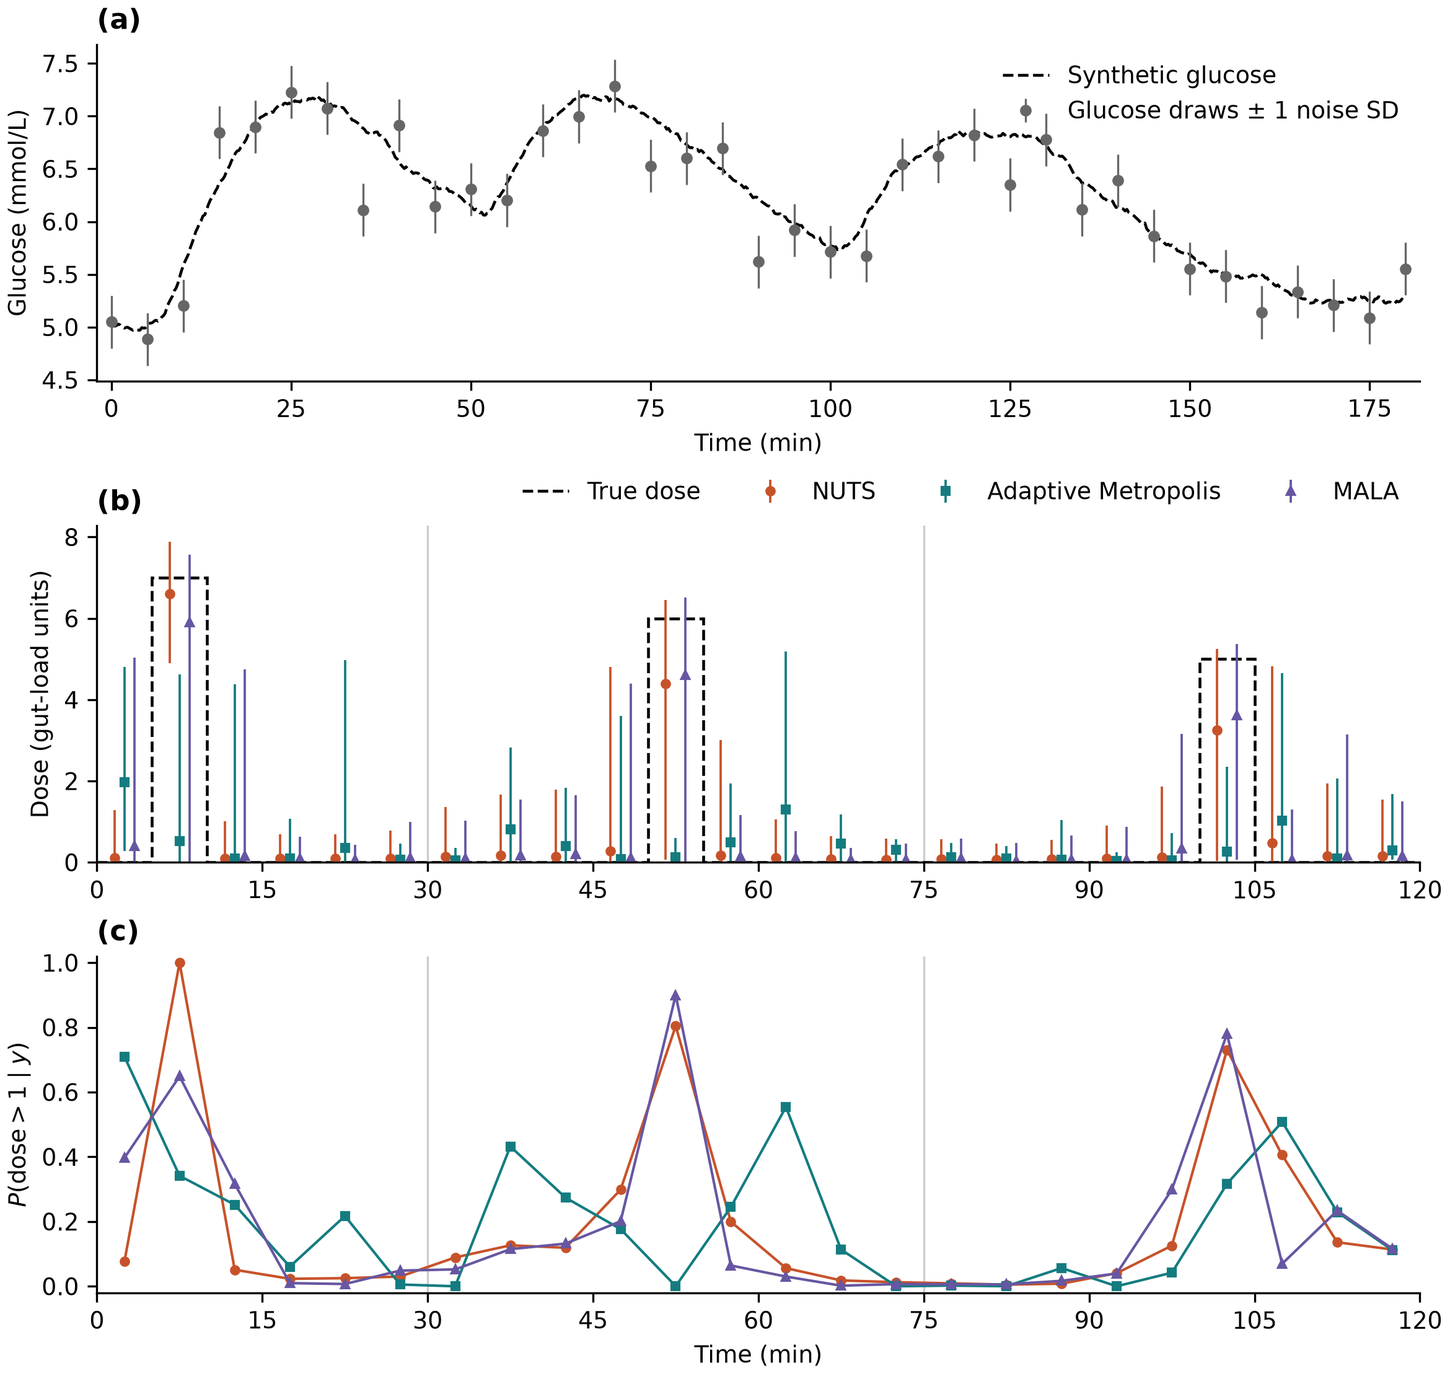

In [ ]:
centers = np.asarray(BIN_EDGES[:-1]) + BIN_MINUTES / 2

with plt.rc_context({
    "font.size": 9, "axes.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False,
    "xtick.direction": "out", "ytick.direction": "out",
}):
    fig, axes = plt.subplots(3, 1, figsize=(7.8, 7.4), layout="constrained")
    glucose, doses, exceedance = axes
    glucose.plot(sim_times, true_states[:, 0], "--", color="black", lw=1.1, label="Synthetic glucose")
    glucose.errorbar(
        OBS_TIMES, observations[:, 0], yerr=OBS_SD, fmt="o", color="#666666",
        ms=3.5, lw=0.8, label="Glucose draws ± 1 noise SD",
    )
    glucose.set(xlim=(-2, 182), xlabel="Time (min)", ylabel="Glucose (mmol/L)")
    glucose.legend(loc="upper right")

    doses.stairs(TRUE_DOSE, BIN_EDGES, linestyle="--", color="black", lw=1.1, label="True dose")
    for method, offset in zip(METHODS, (-0.9, 0, 0.9), strict=True):
        marker = MARKERS[method]
        bins = comparison.xs(method, level="sampler").loc[bin_names]
        doses.errorbar(
            centers + offset, bins["median"],
            yerr=[bins["median"] - bins["q05"], bins["q95"] - bins["median"]],
            fmt=marker, color=COLORS[method], ms=3, lw=0.9, label=method,
        )
        probability = (dose_draws[method] > DOSE_THRESHOLD).mean(axis=(0, 1))
        exceedance.plot(centers, probability, marker=marker, color=COLORS[method], ms=3, lw=1)

    for ax in (doses, exceedance):
        ax.set_xlim(0, 120)
        ax.set_xticks(np.arange(0, 121, 15))
    for edge in (30, 75):
        for ax in (doses, exceedance):
            ax.axvline(edge, color="#cccccc", lw=0.8, zorder=0)
    doses.set(ylabel="Dose (gut-load units)", ylim=(0, None))
    doses.legend(loc="lower right", bbox_to_anchor=(1, 1), ncols=4)
    exceedance.set(xlabel="Time (min)", ylabel=r"$P(\mathrm{dose}>1\mid y)$", ylim=(-0.02, 1.02))
    for ax, panel in zip(axes, ("(a)", "(b)", "(c)"), strict=True):
        ax.set_title(panel, loc="left", fontweight="bold")

    fig.savefig(OUT / "feeding_recovery.png", dpi=300)
    fig.savefig(OUT / "feeding_recovery.pdf")
    plt.show()

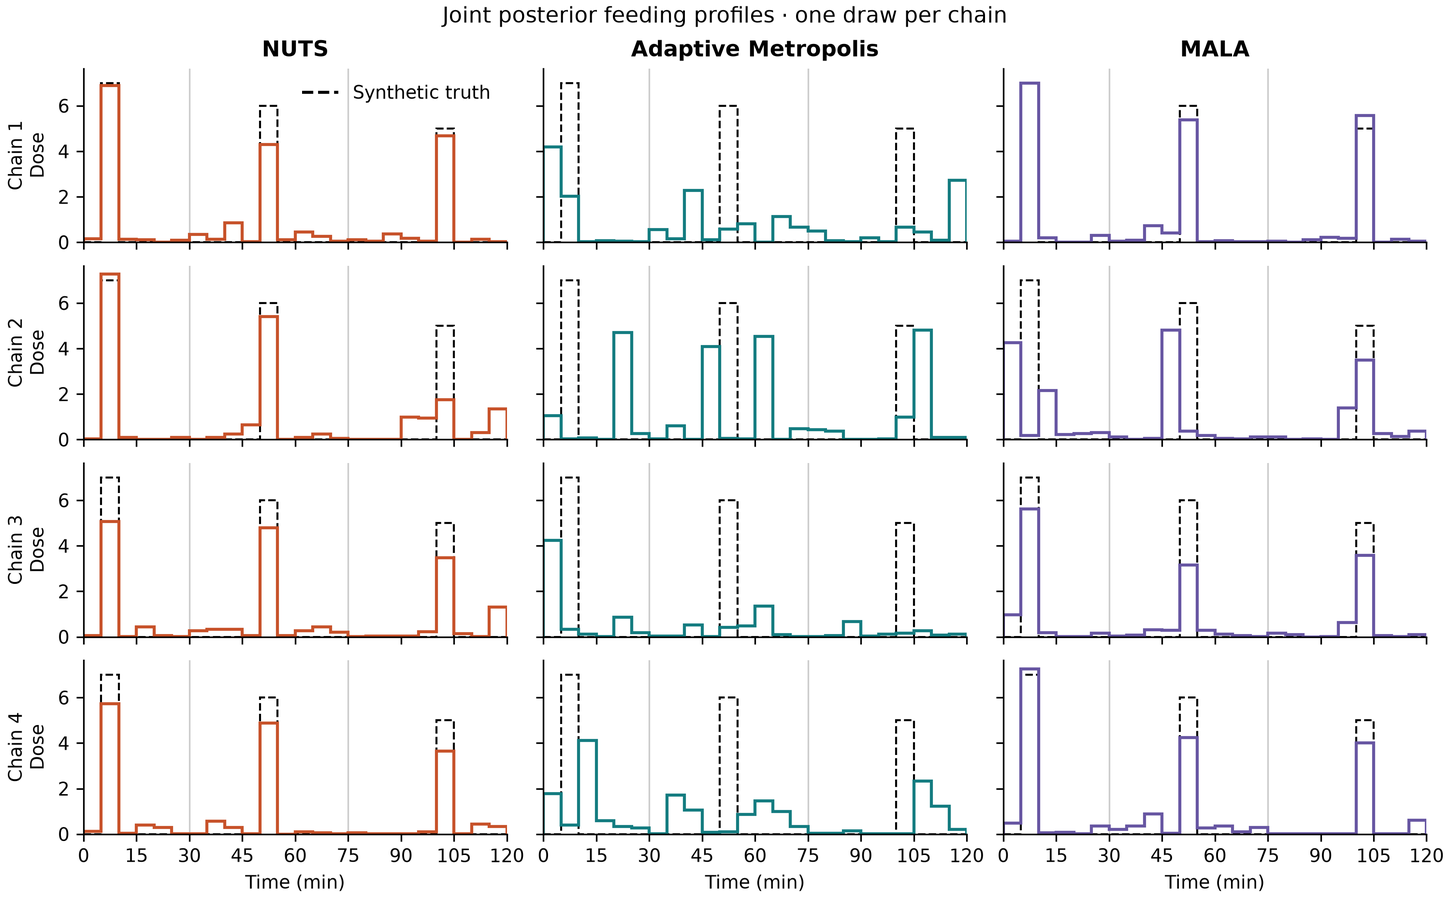

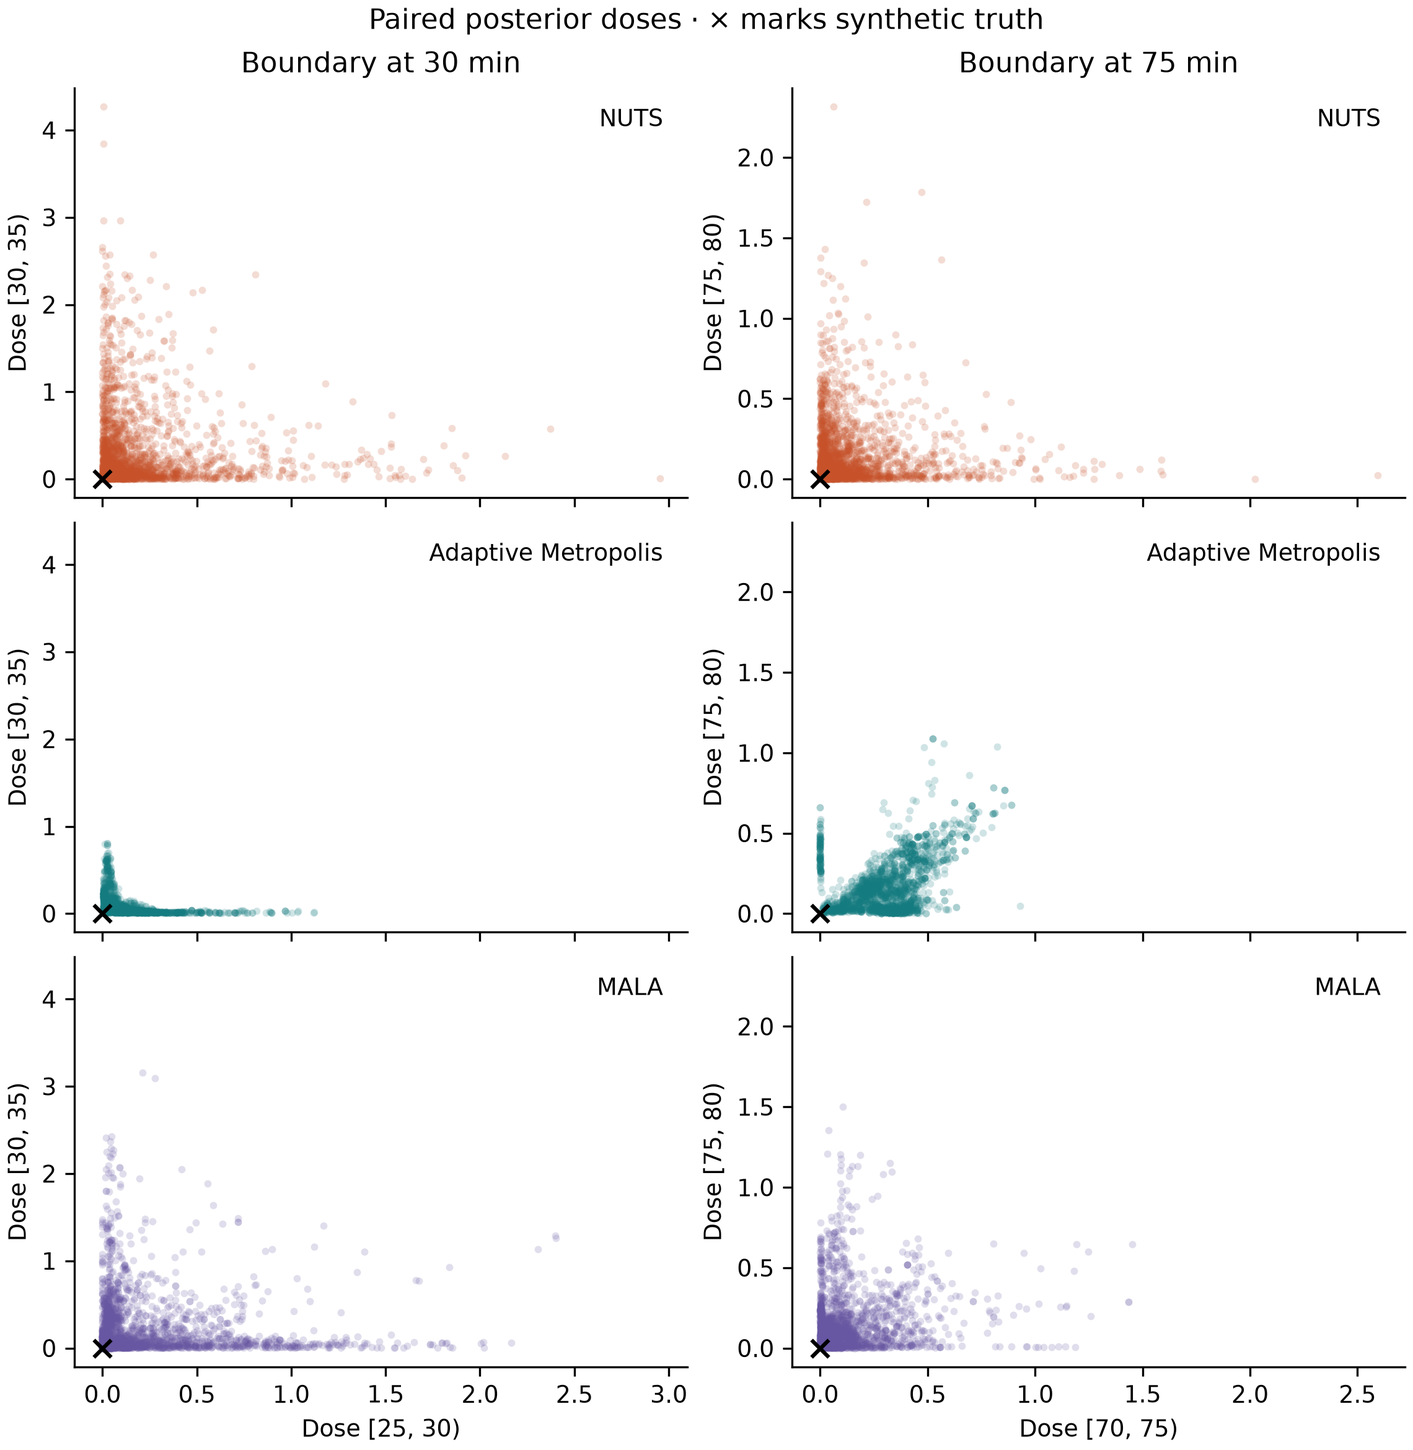

In [ ]:
from matplotlib.lines import Line2D

edges = np.asarray(BIN_EDGES)
truth = np.asarray(TRUE_DOSE)
boundaries = (30, 75)
rng = np.random.default_rng(2026)

style = {
    "font.size": 9,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "xtick.direction": "out",
    "ytick.direction": "out",
}

with plt.rc_context(style):
    n_chains = dose_draws[METHODS[0]].shape[0]
    fig, axes = plt.subplots(
        n_chains,
        len(METHODS),
        figsize=(10, 1.35 * n_chains + 0.8),
        sharex=True,
        sharey=True,
        squeeze=False,
        layout="constrained",
    )

    for col, method in enumerate(METHODS):
        draws = dose_draws[method]
        axes[0, col].set_title(method, fontweight="bold")
        for chain, ax in enumerate(axes[:, col]):
            draw = rng.integers(draws.shape[1])
            ax.stairs(truth, edges, color="black", linestyle="--", lw=1)
            ax.stairs(draws[chain, draw], edges, color=COLORS[method], lw=1.5)
            for boundary in boundaries:
                ax.axvline(boundary, color="#cccccc", lw=0.8, zorder=0)
            if col == 0:
                ax.set_ylabel(f"Chain {chain + 1}\nDose")
        axes[-1, col].set(
            xlabel="Time (min)",
            xlim=(0, edges[-1]),
            ylim=(0, None),
            xticks=np.arange(0, edges[-1] + 1, 15),
        )

    fig.suptitle("Joint posterior feeding profiles · one draw per chain")
    axes[0, 0].legend(
        handles=[Line2D([], [], color="black", ls="--", label="Synthetic truth")],
        loc="upper right",
    )
    fig.savefig(OUT / "feeding_joint_draws.png", dpi=300)
    fig.savefig(OUT / "feeding_joint_draws.pdf")
    plt.show()

    fig, axes = plt.subplots(
        len(METHODS),
        len(boundaries),
        figsize=(7.6, 7.8),
        sharex="col",
        sharey="col",
        layout="constrained",
    )
    for col, boundary in enumerate(boundaries):
        right = np.searchsorted(edges, boundary)
        left = right - 1
        axes[0, col].set_title(f"Boundary at {boundary} min")
        for row, method in enumerate(METHODS):
            ax = axes[row, col]
            pairs = dose_draws[method][..., [left, right]].reshape(-1, 2)
            keep = rng.choice(len(pairs), size=min(2000, len(pairs)), replace=False)
            ax.scatter(
                pairs[keep, 0],
                pairs[keep, 1],
                s=8,
                color=COLORS[method],
                alpha=0.20,
                linewidths=0,
            )
            ax.scatter(
                truth[left],
                truth[right],
                s=45,
                marker="x",
                color="black",
                zorder=3,
            )
            ax.text(0.96, 0.95, method, transform=ax.transAxes, ha="right", va="top")
            ax.set_ylabel(f"Dose [{boundary}, {edges[right + 1]:g})")
        axes[-1, col].set_xlabel(f"Dose [{edges[left]:g}, {boundary})")

    fig.suptitle("Paired posterior doses · × marks synthetic truth")
    fig.savefig(OUT / "feeding_boundary_pairs.png", dpi=300)
    fig.savefig(OUT / "feeding_boundary_pairs.pdf")
    plt.show()


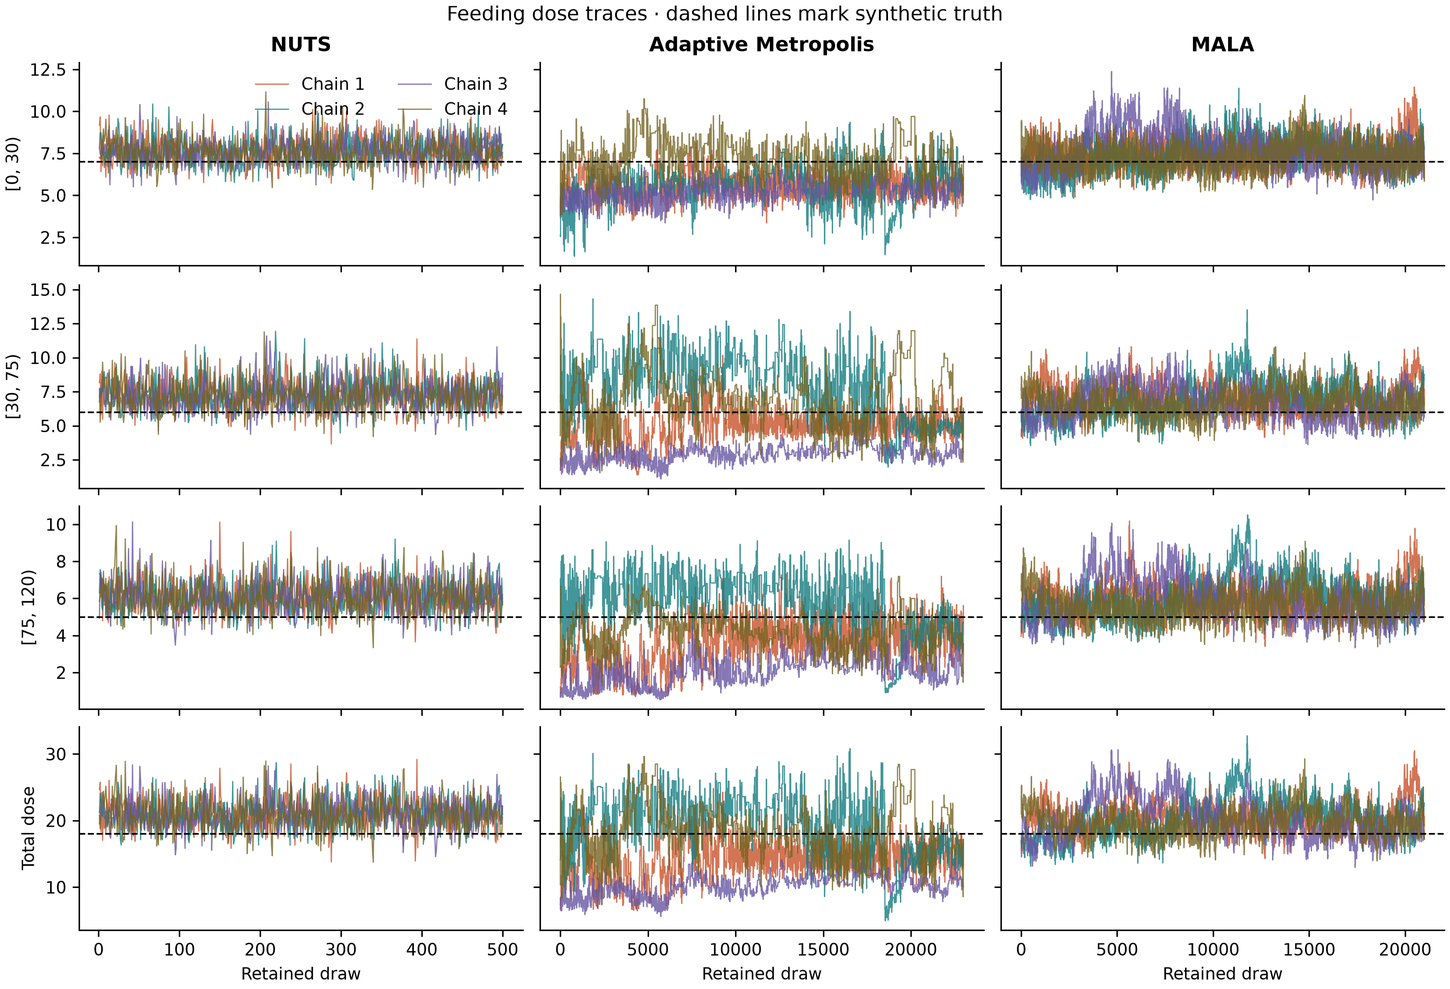

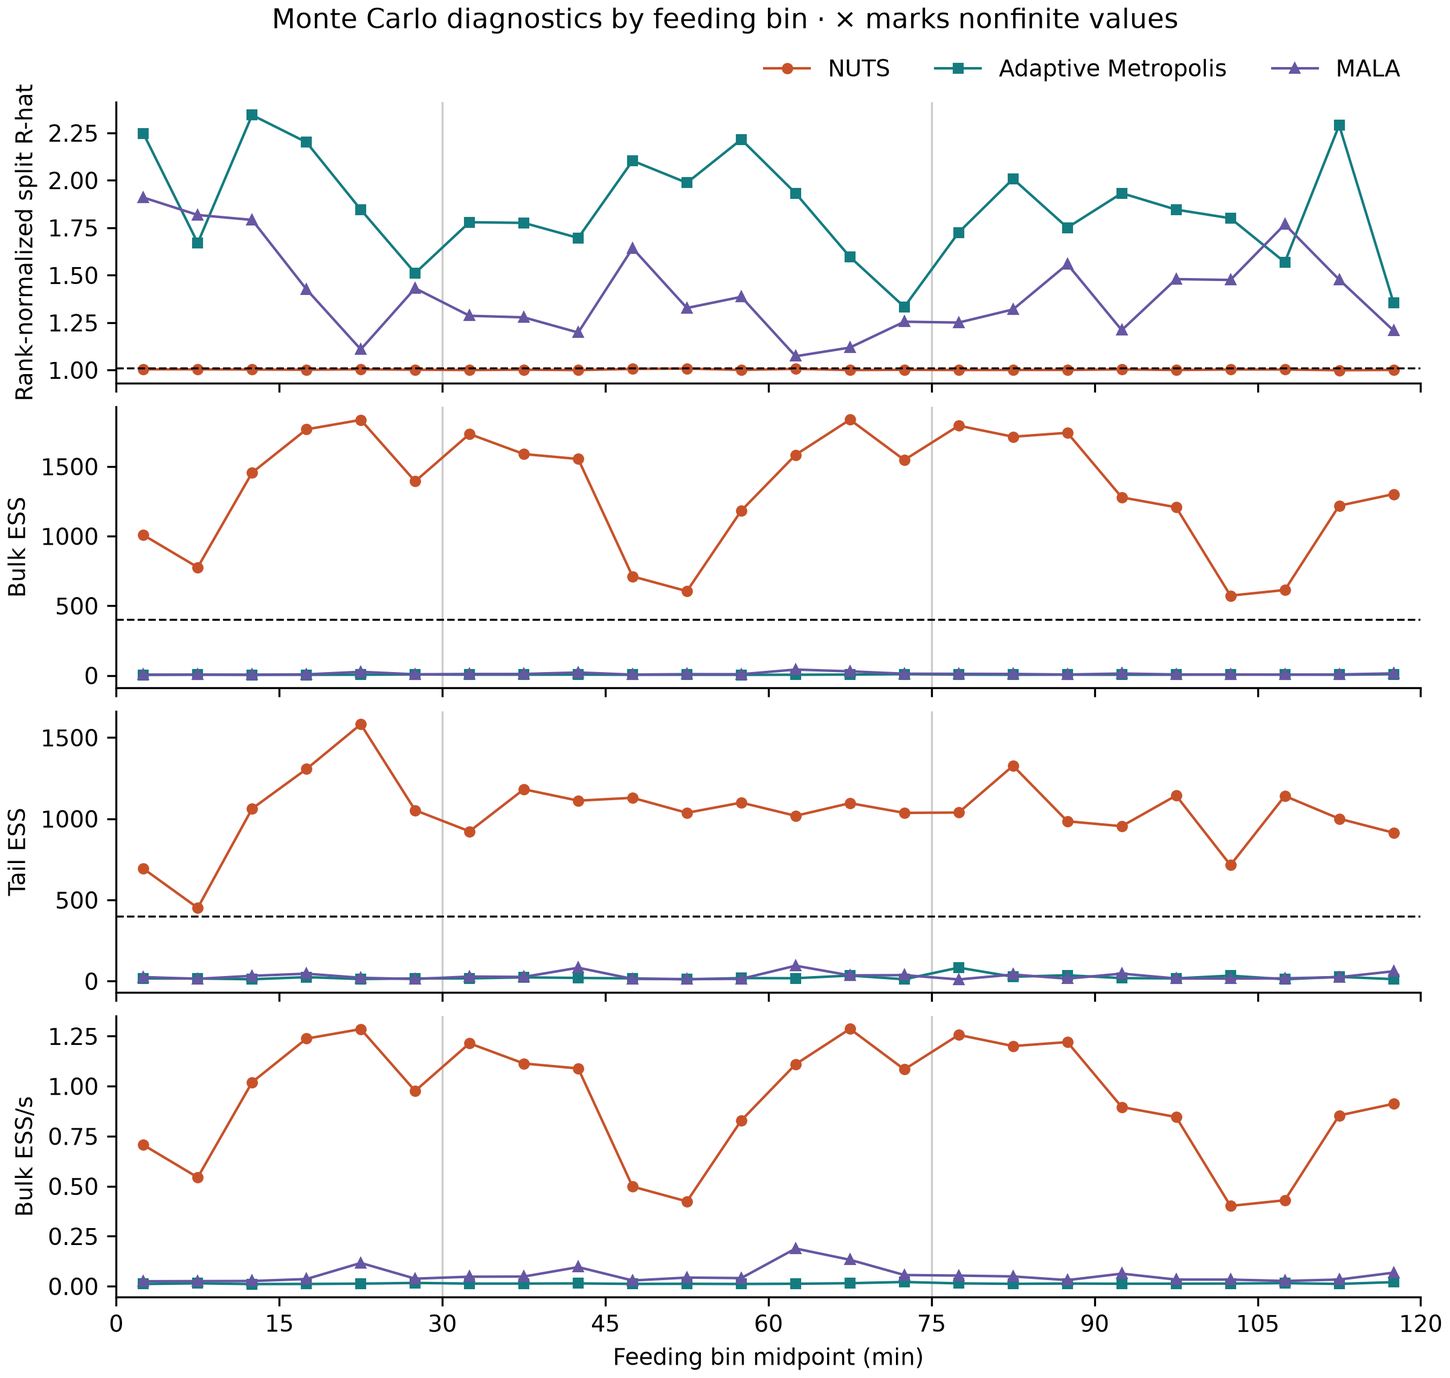

NUTS divergences by chain: [0, 0, 0, 0]


In [ ]:
chain_colors = ("#c7522a", "#147c80", "#6756a2", "#766422")
plot_style = {
    "font.size": 9,
    "axes.linewidth": 0.8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "xtick.direction": "out",
    "ytick.direction": "out",
}

with plt.rc_context(plot_style):
    labels = [*window_masks, "Total dose"]
    fig, axes = plt.subplots(
        len(labels),
        len(METHODS),
        figsize=(11, 7.5),
        sharex="col",
        sharey="row",
        layout="constrained",
    )

    for col, method in enumerate(METHODS):
        dose = dose_draws[method]
        series = {
            label: dose[..., mask].sum(axis=-1) for label, mask in window_masks.items()
        }
        series["Total dose"] = dose.sum(axis=-1)
        axes[0, col].set_title(method, fontweight="bold")

        for row, label in enumerate(labels):
            ax = axes[row, col]
            for chain, values in enumerate(series[label]):
                ax.plot(
                    np.arange(1, len(values) + 1),
                    values,
                    color=chain_colors[chain % len(chain_colors)],
                    lw=0.65,
                    alpha=0.8,
                    label=f"Chain {chain + 1}",
                )
            ax.axhline(true_by_quantity[label], color="black", ls="--", lw=0.9)
            if col == 0:
                ax.set_ylabel(label)
        axes[-1, col].set_xlabel("Retained draw")

    axes[0, 0].legend(ncols=2, loc="upper right")
    fig.suptitle("Feeding dose traces · dashed lines mark synthetic truth")
    fig.savefig(OUT / "feeding_mc_traces.png", dpi=300)
    fig.savefig(OUT / "feeding_mc_traces.pdf")
    plt.show()

    centers = (np.asarray(BIN_EDGES[:-1]) + np.asarray(BIN_EDGES[1:])) / 2
    metrics = [
        ("rank-normalized split R-hat", "Rank-normalized split R-hat", 1.01),
        ("bulk ESS", "Bulk ESS", 400),
        ("tail ESS", "Tail ESS", 400),
        ("bulk ESS/s", "Bulk ESS/s", None),
    ]
    fig, axes = plt.subplots(
        len(metrics),
        1,
        figsize=(8, 7.6),
        sharex=True,
        layout="constrained",
    )

    for ax, (column, label, threshold) in zip(axes, metrics, strict=True):
        for method in METHODS:
            marker = MARKERS[method]
            table = comparison.xs(method, level="sampler").loc[bin_names]
            values = table[column].to_numpy()
            ax.plot(
                centers,
                values,
                color=COLORS[method],
                marker=marker,
                ms=3.5,
                lw=1,
                label=method,
            )
            missing = ~np.isfinite(values)
            if missing.any():
                ax.plot(
                    centers[missing],
                    np.full(missing.sum(), 0.05),
                    "x",
                    transform=ax.get_xaxis_transform(),
                    color=COLORS[method],
                )
        if threshold is not None:
            ax.axhline(threshold, color="black", ls="--", lw=0.8)
        for boundary in (30, 75):
            ax.axvline(boundary, color="#cccccc", lw=0.8, zorder=0)
        ax.set_ylabel(label)

    axes[0].legend(loc="lower right", bbox_to_anchor=(1, 1), ncols=3)
    axes[-1].set(
        xlabel="Feeding bin midpoint (min)",
        xlim=(0, 120),
        xticks=np.arange(0, 121, 15),
    )
    fig.suptitle("Monte Carlo diagnostics by feeding bin · × marks nonfinite values")
    fig.savefig(OUT / "feeding_mc_by_bin.png", dpi=300)
    fig.savefig(OUT / "feeding_mc_by_bin.pdf")
    plt.show()

print("NUTS divergences by chain:", nuts_diagnostics["divergences_per_chain"])
